# Lunar support views required by the environmental EDA

Ported from `notebooks/preprocessing/13_build_lunar_terrain_views.ipynb`. Original source files are unchanged. Inputs and all generated data stay under `darrel stuff/data/`.

Run local notebook 05 first. This is the unchanged support-view construction used by notebook 25: full published elevation context and a separate image-supported view. It is included only to preserve the original joint environmental/terrain coverage analysis, not to add a new terrain study.

**Existing local port, now selected for verified execution.** Uses the completed local notebook-05 preparation and the original source-coverage/halo policy. An additive scalar summary is exported for the environmental pipeline; original terrain methods and the report/gallery are retained. Read `../../EDA_Notes.md` before Run All.


**Preview colours are data-quality labels, not environmental hazard levels.** Magenta in the image-supported elevation panel is missing/unsupported elevation. In `exclusion_reason`: green = complete supported features; blue = source boundary; orange = insufficient image support; red = unsupported neighbourhood; grey = outside the ROI. These masks are preserved, not filled or smoothed.


In [5]:
from pathlib import Path
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "outline.md").is_file() and (p / "notebooks").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository or one of its subfolders")
DATA_ROOT = ROOT / "darrel stuff/data"
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "darrel stuff/EDA"))
from environment_workflow import LocalRun as Run, latest_completed_run, select_climate_manifest

print("Source data:", DATA_ROOT)
print("Processed outputs:", DATA_ROOT / "processed")


Source data: c:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data
Processed outputs: c:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed


In [6]:
import json
import shutil
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
from IPython.display import Image, Markdown, display
from rasterio.crs import CRS
from rasterio.enums import Resampling
from scipy.ndimage import minimum_filter

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'outline.md').exists())
sys.path.insert(0, str(ROOT))
from notebooks.shared.processing import (
    MOON_CRS,
    Grid,
    pad_grid,
    rectangular_coverage,
    sha256,
    terrain,
    warp,
    write_raster,
)

SOURCE_RUN_ID = None  # Set an explicit completed local notebook-05 run ID to pin it.
OLD = latest_completed_run(ROOT, 'lunar_terrain_environment', SOURCE_RUN_ID)
RAW = DATA_ROOT / 'moon/sdem/regions'
FEATURES = ['elevation_m', 'relative_elevation_m', 'slope_deg', 'laplacian_per_m', 'local_elevation_std_m']
SPACING = 30
WINDOW = 11
HALO = WINDOW // 2
COVERAGE_TOLERANCE = 1e-6
EXPECTED_REGIONS = {
    'A3CLR22_10_Leibnitz_Beta_Plateau', 'A3CLR22_11_Malapert_Massif',
    'A3CLR22_12_deGerlache_Kocher_Massif', 'A3CLR22_2_Haworth', 'A3CLR22_3_Faustini_Rim_A',
    'A3CLR22_4_deGerlache_Rim_2', 'A3CLR22_5_Connecting_Ridge_Extension',
}
record = json.loads((OLD / 'provenance.json').read_text())
assert record['status'] == 'complete'
expected_hashes = {item['path']: item['sha256'] for item in record['outputs']}
folders = sorted((OLD / 'moon').glob('*/grid_30m'))
assert {p.parent.name for p in folders} == EXPECTED_REGIONS
source_bounds = {}
for region in sorted(EXPECTED_REGIONS):
    paths = list((RAW / region).glob('*_GLDELEV_005.tif'))
    assert len(paths) == 1
    with rasterio.open(paths[0]) as src:
        assert src.crs == CRS.from_string(MOON_CRS)
        source_bounds[region] = tuple(src.bounds)
for region, (w, s, e, n) in source_bounds.items():
    neighbors = [other for other, (ow, os, oe, on) in source_bounds.items() if other != region
                 and min(e + HALO*SPACING, oe) > max(w - HALO*SPACING, ow)
                 and min(n + HALO*SPACING, on) > max(s - HALO*SPACING, os)]
    assert not neighbors, f'New overlapping source coverage requires an explicit mosaic policy: {region}, {neighbors}'
print('Seven regions verified; no downloaded neighboring SDEM covers their 150 m halos.')


Accepted local lunar_terrain_environment run: 20261106T180253772848Z_40d3f3
Seven regions verified; no downloaded neighboring SDEM covers their 150 m halos.


In [7]:
config = {'source_run': str(OLD.relative_to(ROOT)), 'spacing_m': SPACING,
          'roughness_window': WINDOW, 'halo_cells': HALO, 'complete_source_coverage_tolerance': COVERAGE_TOLERANCE,
          'supported_view': 'byte-identical copies of pinned existing view',
          'context_view': 'mean full published source elevation; no external fill; full-cell neighborhoods for derivatives',
          'neighborhood_boundary_policy': 'real source pixels only; no extrapolation or reflection'}
summaries = []
with rasterio.Env(GDAL_CACHEMAX=32*1024**2), Run(ROOT, 'lunar_terrain_views', config, 'Moon/Terrain_And_Soil/13_build_lunar_terrain_views.ipynb') as run:
    run.input(ROOT/'notebooks/preprocessing/13_build_lunar_terrain_views.ipynb')
    run.input(OLD / 'provenance.json')
    for folder in folders:
        region = folder.parent.name
        prefix = f'moon/{region}'
        with rasterio.open(folder / 'elevation_m.tif') as src:
            grid = Grid(src.crs, src.transform, src.width, src.height)
            assert src.res == (SPACING, SPACING)
        strict_joint = np.ones((grid.height, grid.width), dtype=bool)
        strict_elevation_valid = None
        for feature in FEATURES + ['image_support_fraction']:
            path = folder / (feature + '.tif')
            assert sha256(path) == expected_hashes[str(path.relative_to(OLD))], path
            run.input(path)
            target = run.path(f'{prefix}/image_supported/{feature}.tif')
            shutil.copyfile(path, target)
            assert sha256(target) == expected_hashes[str(path.relative_to(OLD))]
            with rasterio.open(path) as src:
                assert (src.shape, src.transform, src.crs) == ((grid.height, grid.width), grid.transform, grid.crs)
                values = src.read(1, masked=True).astype('float32').filled(np.nan)
            if feature == 'image_support_fraction':
                fraction = values
            else:
                strict_joint &= np.isfinite(values)
                if feature == 'elevation_m':
                    strict_elevation_valid = np.isfinite(values)
        inside = np.isfinite(fraction)
        assert strict_elevation_valid is not None
        source = next((RAW / region).glob('*_GLDELEV_005.tif'))
        masks = list((RAW / region).glob('*_GLDMASK_005.tif'))
        assert len(masks) == 1
        mask_source = masks[0]
        for path in [source, mask_source, RAW / region / 'README.txt']:
            run.input(path)
        with rasterio.open(mask_source) as src:
            assert src.crs == grid.crs
            mask_bounds = tuple(src.bounds)
        work_grid = pad_grid(grid, HALO)
        core = (slice(HALO, HALO + grid.height), slice(HALO, HALO + grid.width))
        work_inside = np.zeros((work_grid.height, work_grid.width), dtype=bool)
        work_inside[core] = inside
        coverage = rectangular_coverage(work_grid, source_bounds[region])
        full = warp(source, work_grid, resampling=Resampling.average)
        full[coverage == 0] = np.nan
        context_elevation = full[core].copy()
        context_elevation[~inside] = np.nan
        assert np.isfinite(context_elevation[inside]).all(), region
        supported_source_cells = (coverage >= 1-COVERAGE_TOLERANCE) & np.isfinite(full)
        derivative_input = np.where(supported_source_cells, full, np.nan)
        features = terrain(derivative_input, SPACING, WINDOW, output_mask=work_inside)
        # Relative elevation is context over the entire ROI, including explicitly flagged partial edge pixels.
        features['relative_elevation_m'] = full - float(np.median(context_elevation[inside]))
        features['elevation_m'] = full
        context_joint = inside.copy()
        for feature in FEATURES:
            result = features[feature][core].copy()
            result[~inside] = np.nan
            context_joint &= np.isfinite(result)
            units = 'degree' if feature == 'slope_deg' else '1/m' if feature == 'laplacian_per_m' else 'm'
            write_raster(run.path(f'{prefix}/full_context/{feature}.tif'), result, grid, units,
                         terrain_view='full published elevation context; image support varies',
                         vertical_reference='radius 1737400 m')
        footprint_complete = coverage >= 1-COVERAGE_TOLERANCE
        edge_slope = inside & ~minimum_filter(footprint_complete.astype('uint8'), size=3,
                                             mode='constant', cval=0).astype(bool)[core]
        edge_roughness = inside & ~minimum_filter(footprint_complete.astype('uint8'), size=WINDOW,
                                                 mode='constant', cval=0).astype(bool)[core]
        reason = np.where(strict_joint, 1, np.where(edge_roughness, 2, np.where(fraction < .99, 3, 4)))
        quality = {
            'source_coverage_fraction': coverage[core],
            'count_map_coverage_fraction': rectangular_coverage(grid, mask_bounds),
            'source_edge_slope_exclusion_mask': edge_slope,
            'source_edge_roughness_exclusion_mask': edge_roughness,
            'image_supported_complete_feature_mask': strict_joint,
            'full_context_complete_feature_mask': context_joint,
            'strict_exclusion_reason': reason,
        }
        for name, values in quality.items():
            output = values.astype('float32').copy()
            output[~inside] = np.nan
            write_raster(run.path(f'{prefix}/quality/{name}.tif'), output, grid,
                         'fraction' if name.endswith('fraction') else 'category' if name.endswith('reason') else 'binary')
        # Source-boundary flags must exclude derivatives without real source neighborhoods.
        assert not np.isfinite(features['slope_deg'][core][edge_slope]).any()
        assert not np.isfinite(features['local_elevation_std_m'][core][edge_roughness]).any()
        restored = inside & ~strict_elevation_valid & np.isfinite(context_elevation)
        summaries.append({'region': region, 'roi_cells': int(inside.sum()),
                          'context_elevation_cells_restored': int(restored.sum()),
                          'strict_complete_feature_cells': int(strict_joint.sum()),
                          'context_complete_feature_cells': int(context_joint.sum()),
                          'context_roughness_source_edge_exclusions': int(edge_roughness.sum()),
                          'partial_elevation_footprint_cells': int((inside & (coverage[core] < 1-COVERAGE_TOLERANCE)).sum()),
                          'partial_count_map_footprint_cells': int((inside & (quality['count_map_coverage_fraction'] < 1-COVERAGE_TOLERANCE)).sum()),
                          'strict_missing_primary_causes': {str(i): int((inside & (reason == i)).sum()) for i in [2, 3, 4]}})
        print(region, summaries[-1], flush=True)
    run.path('summary.json').write_text(json.dumps(summaries, indent=2), encoding='utf-8')
    pd.DataFrame(summaries).drop(columns='strict_missing_primary_causes').to_csv(run.path('terrain_view_support_summary.csv'),index=False)
    report = '# Full lunar terrain and image-supported terrain\n\n'
    report += f"Restored {sum(r['context_elevation_cells_restored'] for r in summaries):,} finite source heights in the separate full-context view. "
    report += 'The original image-supported view is copied byte-for-byte. No fill or invented elevations were used.\n\n'
    report += 'Outer feature bands remain excluded where their required neighborhoods extend beyond the source. '
    report += 'Use complete-feature masks for whole-patch selection; get compatible larger-extent source data to recover these derivatives. '
    report += 'Do not treat full-context availability as independent image support.\n\n'
    report += 'Quality layers distinguish partial source/count-map footprints, source-edge neighborhoods, and image-support exclusions. '
    report += 'Source-edge roughness flags include the 150 m neighborhood radius and any partial boundary pixels.\n'
    run.path('REPORT.md').write_text(report, encoding='utf-8')
print('New terrain views:', run.directory)
display(pd.DataFrame(summaries).drop(columns='strict_missing_primary_causes'))


A3CLR22_10_Leibnitz_Beta_Plateau {'region': 'A3CLR22_10_Leibnitz_Beta_Plateau', 'roi_cells': 284089, 'context_elevation_cells_restored': 18420, 'strict_complete_feature_cells': 195828, 'context_complete_feature_cells': 273529, 'context_roughness_source_edge_exclusions': 10560, 'partial_elevation_footprint_cells': 0, 'partial_count_map_footprint_cells': 533, 'strict_missing_primary_causes': {'2': 10560, '3': 16812, '4': 60889}}
A3CLR22_11_Malapert_Massif {'region': 'A3CLR22_11_Malapert_Massif', 'roi_cells': 490000, 'context_elevation_cells_restored': 12213, 'strict_complete_feature_cells': 392617, 'context_complete_feature_cells': 475410, 'context_roughness_source_edge_exclusions': 14590, 'partial_elevation_footprint_cells': 700, 'partial_count_map_footprint_cells': 700, 'strict_missing_primary_causes': {'2': 13967, '3': 11518, '4': 71898}}
A3CLR22_12_deGerlache_Kocher_Massif {'region': 'A3CLR22_12_deGerlache_Kocher_Massif', 'roi_cells': 443556, 'context_elevation_cells_restored': 16318

,region,roi_cells,context_elevation_cells_restored,strict_complete_feature_cells,context_complete_feature_cells,context_roughness_source_edge_exclusions,partial_elevation_footprint_cells,partial_count_map_footprint_cells
0,A3CLR22_10_Leibnitz_Beta_Plateau,284089,18420,195828,273529,10560,0,533
1,A3CLR22_11_Malapert_Massif,490000,12213,392617,475410,14590,700,700
2,A3CLR22_12_deGerlache_Kocher_Massif,443556,16318,372363,430336,13220,0,0
3,A3CLR22_2_Haworth,986049,84372,517901,966289,19760,0,1985
4,A3CLR22_3_Faustini_Rim_A,444222,110035,183867,430336,13886,666,666
5,A3CLR22_4_deGerlache_Rim_2,444889,35538,301857,430336,14553,1333,1333
6,A3CLR22_5_Connecting_Ridge_Extension,444889,21343,336044,430336,14553,1333,1333


c:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\.venv\Lib\site-packages\rasterio\__init__.py:389: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(


**Faustini: full_context**

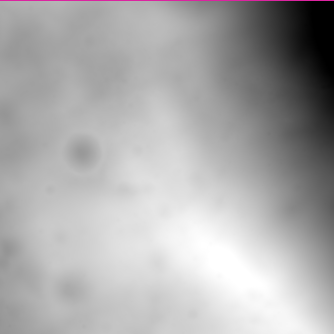

**Faustini: image_supported**

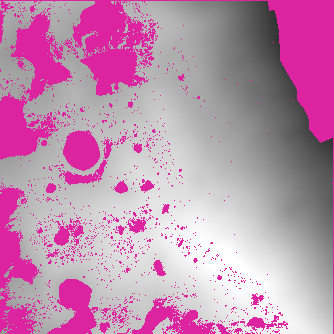

**Faustini: exclusion_reason**

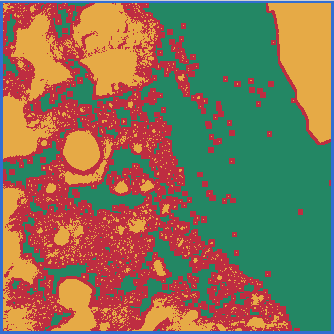

# Full lunar terrain and image-supported terrain

Restored 298,239 finite source heights in the separate full-context view. The original image-supported view is copied byte-for-byte. No fill or invented elevations were used.

Outer feature bands remain excluded where their required neighborhoods extend beyond the source. Use complete-feature masks for whole-patch selection; get compatible larger-extent source data to recover these derivatives. Do not treat full-context availability as independent image support.

Quality layers distinguish partial source/count-map footprints, source-edge neighborhoods, and image-support exclusions. Source-edge roughness flags include the 150 m neighborhood radius and any partial boundary pixels.


Verified outputs: 129 | gallery: c:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\reports\analysis\lunar-terrain-views-20261109T145602402974Z_ffaee2\gallery.html


In [8]:
new_record = json.loads((run.directory / 'provenance.json').read_text())
assert new_record['status'] == 'complete'
for item in new_record['outputs']:
    assert sha256(run.directory / item['path']) == item['sha256'], item['path']
for folder in folders:
    for feature in FEATURES + ['image_support_fraction']:
        path = folder / (feature + '.tif')
        assert sha256(path) == expected_hashes[str(path.relative_to(OLD))]
REPORTS = DATA_ROOT / 'reports/analysis' / ('lunar-terrain-views-' + run.directory.name)
REPORTS.mkdir(parents=True, exist_ok=False)
gallery = ['<!doctype html><meta charset="utf-8"><h1>Full context and image-supported terrain</h1>',
           ('<p>Black/white represent low/high elevation; magenta is missing. '
           'Reason map: green=complete supported features, blue=boundary, orange=image support, red=unsupported neighborhood, gray=outside ROI.</p>')]
display(Markdown(
    '**Preview legend (data quality, not hazard):** elevation black/white = low/high; '
    '**magenta = missing/unsupported** in the displayed view. '
    'Exclusion reasons: **green** = complete supported features; **blue** = source boundary; '
    '**orange** = insufficient image support; **red** = unsupported neighbourhood; '
    '**grey** = outside ROI. Full-context elevation does not imply image-supported measurements.'
))
for region in sorted(EXPECTED_REGIONS):
    prefix = run.directory / 'moon' / region
    panels = {}
    for view in ['full_context', 'image_supported']:
        with rasterio.open(prefix / view / 'elevation_m.tif') as src:
            panels[view] = src.read(1, masked=True).filled(np.nan)
    lo, hi = np.nanquantile(panels['full_context'], [.01, .99])
    stride = max(1, int(np.ceil(max(panels['full_context'].shape) / 600)))
    gallery.append(f'<h2>{region}</h2><p>Elevation display: {lo:.1f} to {hi:.1f} m; previews are decimated.</p>')
    with rasterio.open(prefix / 'quality/strict_exclusion_reason.tif') as src:
        reasons = src.read(1, masked=True).filled(0).astype('uint8')[::stride, ::stride]
    colors = np.array([[210,210,210],[35,135,100],[50,110,210],[230,170,70],[190,45,65]], dtype='uint8')
    for view in ['full_context', 'image_supported', 'exclusion_reason']:
        if view == 'exclusion_reason':
            rgb = colors[reasons]
        else:
            values = panels[view][::stride, ::stride]
            gray = (255*np.clip(np.nan_to_num((values-lo)/max(hi-lo,1e-12)),0,1)).astype('uint8')
            rgb = np.repeat(gray[:,:,None],3,axis=2)
            rgb[~np.isfinite(values)] = [220,35,160]
        filename = f'{region}_{view}.png'
        with rasterio.open(REPORTS / filename, 'w', driver='PNG', width=rgb.shape[1], height=rgb.shape[0], count=3, dtype='uint8') as dst:
            dst.write(rgb.transpose(2,0,1))
        gallery.append(f'<figure><figcaption>{view}</figcaption><img width="400" src="{filename}" alt="{view}"></figure>')
        if region == 'A3CLR22_3_Faustini_Rim_A':
            display(Markdown(f'**Faustini: {view}**'))
            display(Image(filename=str(REPORTS / filename), width=450))
(REPORTS / 'gallery.html').write_text('\n'.join(gallery), encoding='utf-8')
(REPORTS / 'verification.json').write_text(json.dumps({
    'status': 'complete', 'run': str(run.directory.relative_to(ROOT)),
    'new_outputs_hash_verified': len(new_record['outputs']), 'original_supported_files_hash_verified': len(folders)*6,
    'summaries': summaries,
}, indent=2), encoding='utf-8')
display(Markdown((run.directory / 'REPORT.md').read_text(encoding='utf-8')))
print('Verified outputs:', len(new_record['outputs']), '| gallery:', REPORTS / 'gallery.html')
